# BRBseq and WGS sample ID QC

Check identity matches from the combined gill/WGS and liver/WGS relatedness outputs, then compare independent WGS, gill BRB, and liver BRB ancestry results against recorded population and ecotype.

Analysis IDs end in _D (WGS), _G (gill), or _L (liver). ADMIXTURE component labels are independent between runs, so Q1 in one dataset is not assumed to correspond to Q1 in another.

In [28]:
library(dplyr)
library(tidyr)
library(ggplot2)
library(readr)

find_repo_root <- function(start = getwd()) {
  candidates <- normalizePath(c(start, file.path(start, '..')), mustWork = FALSE)
  hit <- candidates[file.exists(file.path(candidates, 'config', 'brb_pipeline_config.sh'))]
  if (!length(hit)) stop('Could not find Gacu_BC_txmics repo root from: ', start)
  hit[[1]]
}
repo_root <- find_repo_root()
genotype_root <- file.path(repo_root, 'outputs', 'genotypes')
plink_root <- file.path(genotype_root, 'plink')
relatedness_root <- file.path(genotype_root, 'relatedness')
mapping_file <- file.path(repo_root, 'metadata', 'derived', 'sample_source_mapping.tsv')
stopifnot(file.exists(mapping_file))
sample_map <- read_tsv(mapping_file, show_col_types = FALSE) %>%
  distinct(analysis_id, .keep_all = TRUE) %>%
  mutate(
    base_id = sub("_[DGL]$", "", analysis_id),
    ecotype_plot = coalesce(
      na_if(tolower(trimws(ecotype)), ""),
      na_if(tolower(trimws(site_type)), "")
    )
  )

# Review the CV plot later, then set selected_k before loading ancestry Q files.
k_values <- 8:28
datasets <- c(wgs = 'wgs', gill = 'gill_brb', liver = 'liver_brb')
cat('Repo:', repo_root, '\nMapped analysis IDs:', nrow(sample_map), '\n')
sample_map %>% count(source, tissue)

Repo: /scratch/ztobias/Gacu_BC_txmics 
Mapped analysis IDs: 1915 


source,tissue,n
<chr>,<chr>,<int>
BRB,gill,630
BRB,liver,639
WGS,DNA,646


In [6]:
anti_join(
  sample_map %>% filter(source == "BRB", tissue == "gill") %>% distinct(base_id),
  sample_map %>% filter(source == "WGS") %>% distinct(base_id),
  by = "base_id"
)

anti_join(
  sample_map %>% filter(source == "BRB", tissue == "liver") %>% distinct(base_id),
  sample_map %>% filter(source == "WGS") %>% distinct(base_id),
  by = "base_id"
)

base_id
<chr>
2024_DJR_196
2024_DJR_393
2024_DJR_394
2024_DJR_395
2024_DJR_402
2024_DJR_406
2025_DJR_021
2025_DJR_027
2025_DJR_177


base_id
<chr>
2024_DJR_196
2024_DJR_393
2024_DJR_394
2024_DJR_395
2024_DJR_402
2024_DJR_406
2025_DJR_021
2025_DJR_027
2025_DJR_457


## Identity matching from combined-panel relatedness

For every BRB sample, compare PI_HAT to the WGS ID with the same base ID against the strongest alternative WGS match. An expected match that ranks first and exceeds alternatives supports the recorded identity. An alternative match that ranks first is a candidate to investigate, not an automatic relabeling.

In [2]:
read_identity_comparison <- function(tissue) {
  path <- file.path(relatedness_root, paste0(tissue, '_wgs_brb_relatedness.genome'))
  if (!file.exists(path)) stop('Missing relatedness output: ', path)
  brb_suffix <- if (tissue == 'gill') 'G' else 'L'
  dat <- read.table(path, header = TRUE, check.names = FALSE, stringsAsFactors = FALSE) %>%
    mutate(suffix1 = sub('.*_', '', IID1), suffix2 = sub('.*_', '', IID2)) %>%
    filter((suffix1 == 'D' & suffix2 == brb_suffix) |
           (suffix2 == 'D' & suffix1 == brb_suffix)) %>%
    transmute(
      brb_id = if_else(suffix1 == brb_suffix, IID1, IID2),
      wgs_id = if_else(suffix1 == 'D', IID1, IID2),
      PI_HAT, Z0, Z1, Z2, IBS0, PPC,
      expected_pair = sub('_[DGL]$', '', brb_id) == sub('_[DGL]$', '', wgs_id)
    ) %>%
    group_by(brb_id) %>%
    mutate(wgs_rank = min_rank(desc(PI_HAT))) %>%
    ungroup()
  expected <- dat %>% filter(expected_pair) %>%
    transmute(brb_id, expected_wgs_id = wgs_id, expected_PI_HAT = PI_HAT, expected_rank = wgs_rank)
  alternative <- dat %>% filter(!expected_pair) %>% group_by(brb_id) %>%
    slice_max(PI_HAT, n = 1, with_ties = FALSE) %>% ungroup() %>%
    transmute(brb_id, best_alternative_wgs_id = wgs_id, best_alternative_PI_HAT = PI_HAT)
  brb_ids <- sample_map %>% filter(source == 'BRB', tissue == !!tissue) %>%
    select(brb_id = analysis_id)
  brb_ids %>% left_join(expected, by = 'brb_id') %>%
    left_join(alternative, by = 'brb_id') %>%
    mutate(tissue = tissue, expected_minus_alternative = expected_PI_HAT - best_alternative_PI_HAT) %>%
    left_join(sample_map %>% select(brb_id = analysis_id, population, ecotype = ecotype_plot), by = 'brb_id') %>%
    arrange(expected_rank, desc(expected_PI_HAT))
}
identity_qc <- bind_rows(read_identity_comparison('gill'), read_identity_comparison('liver'))
identity_qc %>% count(tissue, has_expected_pair = !is.na(expected_PI_HAT), expected_is_top_match = expected_rank == 1)
identity_qc %>% select(tissue, brb_id, population, ecotype, expected_wgs_id, expected_PI_HAT, expected_rank,
                        best_alternative_wgs_id, best_alternative_PI_HAT, expected_minus_alternative)

tissue,has_expected_pair,expected_is_top_match,n
<chr>,<lgl>,<lgl>,<int>
gill,FALSE,NA,14
gill,TRUE,FALSE,5
gill,TRUE,TRUE,611
liver,FALSE,NA,9
liver,TRUE,FALSE,7
liver,TRUE,TRUE,623


tissue,brb_id,population,ecotype,expected_wgs_id,expected_PI_HAT,expected_rank,best_alternative_wgs_id,best_alternative_PI_HAT,expected_minus_alternative
<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<int>,<chr>,<dbl>,<dbl>
gill,2025_DJR_060_G,Roberts,NA,2025_DJR_060_D,0.9568,1,2025_DJR_061_D,0.2276,0.7292
gill,2025_DJR_274_G,Comida,NA,2025_DJR_274_D,0.9542,1,2025_DJR_161_D,0.4653,0.4889
gill,2025_DJR_054_G,Roberts,NA,2025_DJR_054_D,0.9541,1,2025_DJR_170_D,0.2365,0.7176
gill,2025_DJR_167_G,Comida,NA,2025_DJR_167_D,0.9532,1,2025_DJR_165_D,0.4891,0.4641
gill,2024_DJR_309_G,Merrill,lake,2024_DJR_309_D,0.9519,1,2024_DJR_303_D,0.5467,0.4052
gill,2025_DJR_296_G,Pye,NA,2025_DJR_296_D,0.9515,1,2025_DJR_249_D,0.5886,0.3629
gill,2025_DJR_328_G,Muchalat,NA,2025_DJR_328_D,0.9512,1,2025_DJR_315_D,0.7800,0.1712
gill,2025_DJR_314_G,Muchalat,NA,2025_DJR_314_D,0.9499,1,2025_DJR_315_D,0.7773,0.1726
gill,2025_DJR_168_G,Comida,NA,2025_DJR_168_D,0.9495,1,2025_DJR_154_D,0.4793,0.4702


Warning message:
“Removed 23 rows containing missing values (`geom_point()`).”


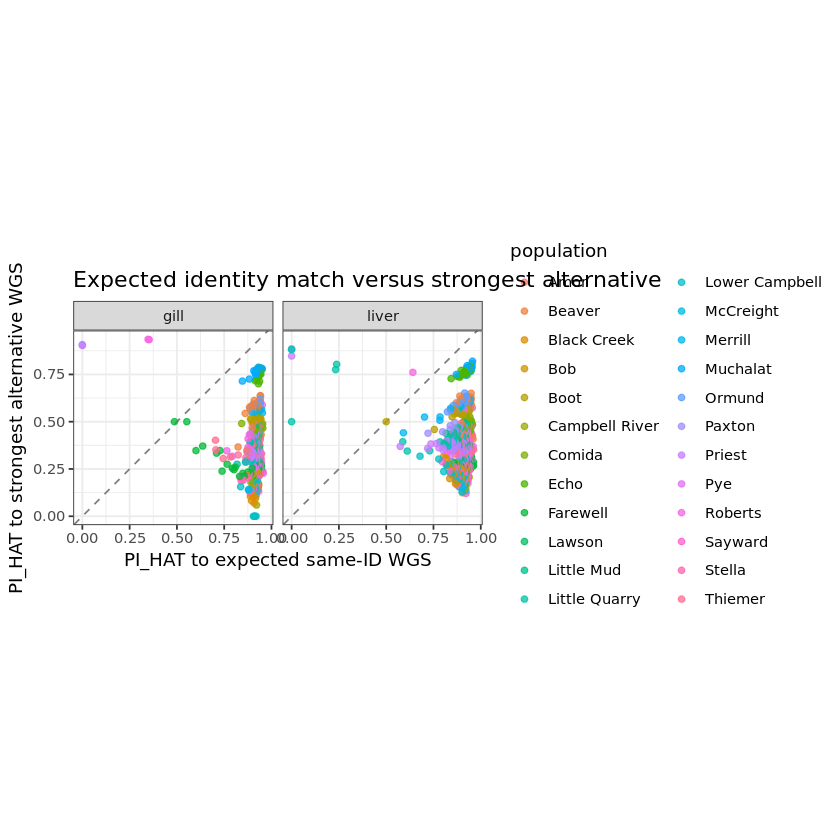

In [7]:
ggplot(identity_qc, aes(expected_PI_HAT, best_alternative_PI_HAT, color = population)) +
  geom_abline(slope = 1, intercept = 0, linetype = 'dashed', color = 'grey50') +
  geom_point(alpha = 0.75) + facet_wrap(~ tissue) + coord_equal() + theme_bw() +
  labs(x = 'PI_HAT to expected same-ID WGS', y = 'PI_HAT to strongest alternative WGS',
       title = 'Expected identity match versus strongest alternative')

In [11]:
top_match_table <- bind_rows(
  read_identity_comparison("gill"),
  read_identity_comparison("liver")
) %>%
  mutate(
    top_match_id = if_else(
      is.na(expected_PI_HAT) | best_alternative_PI_HAT > expected_PI_HAT,
      best_alternative_wgs_id,
      expected_wgs_id
    ),
    top_match_is_self = sub("_[DGL]$", "", brb_id) ==
                        sub("_[DGL]$", "", top_match_id),
    top_match_PI_HAT = if_else(
      is.na(expected_PI_HAT) | best_alternative_PI_HAT > expected_PI_HAT,
      best_alternative_PI_HAT,
      expected_PI_HAT
    )
  ) %>%
  select(
    tissue, brb_id, population, ecotype,
    top_match_id, top_match_PI_HAT,
    expected_PI_HAT, best_alternative_PI_HAT,
    top_match_is_self
  )

top_match_table %>%
  filter(top_match_is_self == FALSE) %>%
  filter(!is.na(expected_PI_HAT))

tissue,brb_id,population,ecotype,top_match_id,top_match_PI_HAT,expected_PI_HAT,best_alternative_PI_HAT,top_match_is_self
<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<lgl>
gill,2025_DJR_286_G,Farewell,NA,2024_DJR_243_D,0.5000,0.4866,0.5000,FALSE
gill,2025_DJR_015_G,Roberts,NA,2025_DJR_016_D,0.9353,0.3476,0.9353,FALSE
gill,2025_DJR_016_G,Roberts,NA,2025_DJR_015_D,0.9336,0.3535,0.9336,FALSE
gill,2024_DJR_041_G,Paxton,benthic,2024_DJR_042_D,0.9078,0.0000,0.9078,FALSE
gill,2024_DJR_042_G,Priest,benthic,2024_DJR_041_D,0.9026,0.0000,0.9026,FALSE
liver,2025_DJR_015_L,Roberts,NA,2025_DJR_016_D,0.7608,0.6410,0.7608,FALSE
liver,2024_DJR_101_L,Little Quarry,limnetic,2024_DJR_102_D,0.8032,0.2381,0.8032,FALSE
liver,2024_DJR_102_L,Little Quarry,limnetic,2024_DJR_103_D,0.7753,0.2328,0.7753,FALSE
liver,2024_DJR_041_L,Paxton,benthic,2024_DJR_042_D,0.8848,0.0000,0.8848,FALSE


Okay so these mostly seem to be ones we already knew about from the BvL analysis. Some Roberts and Farewell

Seems like 2025_DJR_015 and 016 got swapped for gill.

Gotta take a closer look at 2025_DJR_286_G.



Okay yeah that idnetifies those mismatches too but let's look just at the WGS data:

In [20]:
wgs_metadata <- sample_map %>%
  filter(source == "WGS") %>%
  distinct(base_id, population, site_type, ecotype) %>%
  mutate(
    ecotype_plot = coalesce(
      na_if(tolower(trimws(ecotype)), ""),
      na_if(tolower(trimws(site_type)), "")
    )
  )

wgs_pair_values <- read.table(
  file.path(relatedness_root, "gill_wgs_brb_relatedness.genome"),
  header = TRUE, check.names = FALSE
) %>%
  filter(grepl("_D$", IID1), grepl("_D$", IID2)) %>%
  transmute(IID1, IID2, PI_HAT) %>%
  pivot_longer(c(IID1, IID2), values_to = "sample_id") %>%
  group_by(sample_id) %>%
  summarise(
    median_PI_HAT = median(PI_HAT, na.rm = TRUE),
    max_PI_HAT = max(PI_HAT, na.rm = TRUE),
    .groups = "drop"
  ) %>%
  mutate(base_id = sub("_D$", "", sample_id)) %>%
  left_join(wgs_metadata, by = "base_id") %>%
  mutate(
    population_ecotype = interaction(
      population, ecotype_plot, sep = " — ", drop = TRUE
    )
  )

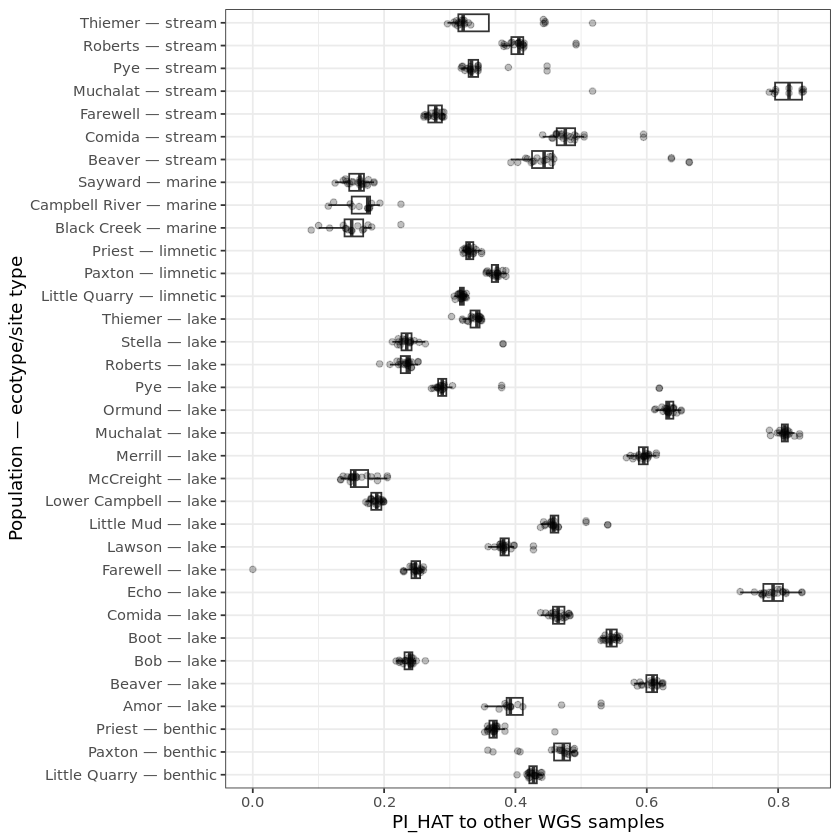

In [24]:
wgs_pair_values_long <- wgs_pair_values %>%
  pivot_longer(
    c(max_PI_HAT, median_PI_HAT),
    names_to = "statistic",
    values_to = "PI_HAT"
  ) %>%
  mutate(
    statistic = recode(
      statistic,
      max_PI_HAT = "Maximum",
      median_PI_HAT = "Median"
    )
  )

ggplot(wgs_pair_values_long %>% filter(statistic=="Maximum"), aes(x = population_ecotype, y = PI_HAT)) +
  geom_boxplot(outlier.shape = NA) +
  geom_jitter(width = 0.15, alpha = 0.25) +
  #facet_wrap(~statistic, ncol = 1) +
  coord_flip() +
  theme_bw() +
  labs(
    x = "Population — ecotype/site type",
    y = "PI_HAT to other WGS samples"
  )

Okay so there are clearly some related samples and especially in some of these lower diversity pops we already knew about like Muchalat and Echo. Medians and means are low so probably driven by a handful of samples. Can look into this later.

## Independent ADMIXTURE results

The CV plot reports results as they become available for K=8–28. Review the curves and choose a K; that same K is then used for each dataset. Q rows are matched to sample IDs in the corresponding PLINK FAM file, so row order must agree. Population summaries and sample flags are calculated separately within each dataset.

dataset,source,tissue,population,ecotype,n_samples
<chr>,<chr>,<chr>,<chr>,<chr>,<int>
gill,BRB,gill,Amor,lake,13
gill,BRB,gill,Beaver,lake,20
gill,BRB,gill,Beaver,stream,20
gill,BRB,gill,Black Creek,marine,20
gill,BRB,gill,Bob,lake,20
gill,BRB,gill,Boot,lake,19
gill,BRB,gill,Campbell River,marine,11
gill,BRB,gill,Comida,lake,20
gill,BRB,gill,Comida,stream,20


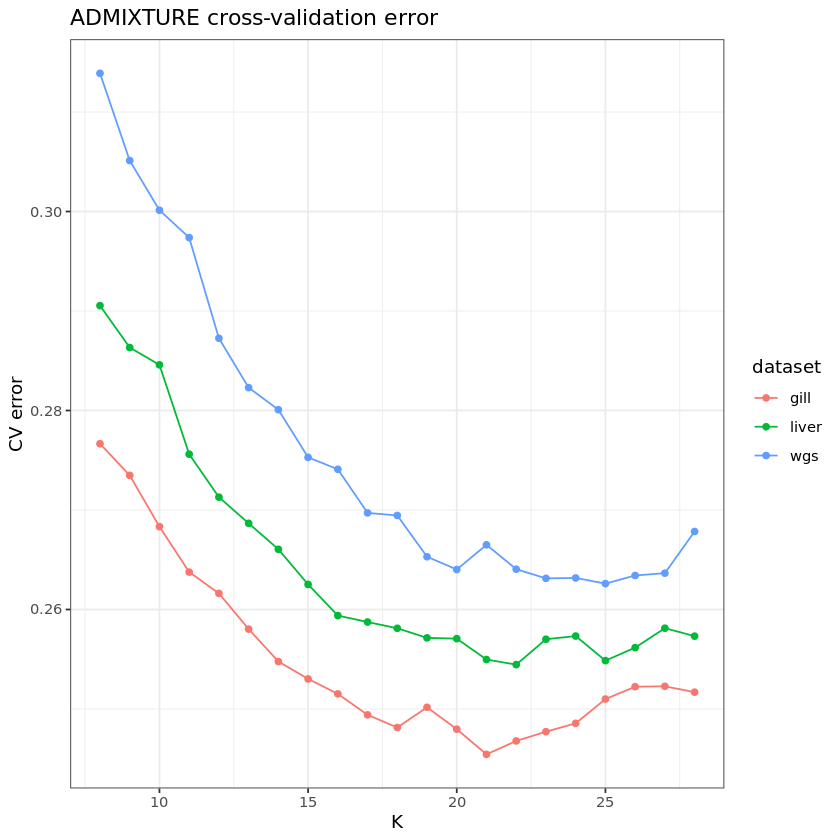

In [29]:
read_cv_error <- function(panel, k) {
  path <- file.path(genotype_root, paste0(panel, '_admixture_K', k, '.log'))
  if (!file.exists(path)) return(NULL)
  cv_line <- grep('CV error', readLines(path, warn = FALSE), value = TRUE)
  if (!length(cv_line)) return(NULL)
  value <- suppressWarnings(as.numeric(sub('.*: *', '', cv_line[[length(cv_line)]])))
  if (!is.finite(value)) return(NULL)
  tibble(dataset = names(datasets)[match(panel, datasets)], K = k, CV_error = value)
}
cv_results <- bind_rows(lapply(unname(datasets), function(panel) {
  bind_rows(lapply(k_values, function(k) read_cv_error(panel, k)))
}))
if (nrow(cv_results)) {
  ggplot(cv_results, aes(K, CV_error, color = dataset)) + geom_line() + geom_point() + theme_bw() +
    labs(title = 'ADMIXTURE cross-validation error', y = 'CV error')
} else message('No ADMIXTURE CV logs found yet.')



Review the CV plot above, then set the K you want to inspect in the next cell. Run the ancestry-loading cell after choosing K.

In [ ]:
selected_k <- NULL  # After reviewing CV, set this to your chosen K, e.g. 22L.

In [ ]:
if (is.null(selected_k)) stop("Review the CV plot and set selected_k before loading ancestry.")
read_admixture <- function(dataset, panel, k = selected_k) {
  prefix <- file.path(plink_root, paste0(panel, "_ldpruned"))
  fam_path <- paste0(prefix, ".fam")
  q_path <- paste0(prefix, ".", k, ".Q")

  if (!file.exists(fam_path) || !file.exists(q_path)) {
    message("Skipping ", dataset, ": expected FAM/Q input is not present yet.")
    return(NULL)
  }

  fam <- read.table(
    fam_path, stringsAsFactors = FALSE,
    col.names = c("FID", "IID", "father", "mother", "sex", "phenotype")
  )
  q <- read.table(q_path, stringsAsFactors = FALSE, check.names = FALSE)

  if (nrow(fam) != nrow(q)) stop("FAM/Q row mismatch for ", dataset)
  names(q) <- paste0("Q", seq_len(ncol(q)))

  bind_cols(tibble(dataset = dataset, analysis_id = fam$IID), as_tibble(q)) %>%
    left_join(
      sample_map %>%
        select(analysis_id, base_id, source, tissue, population,
               ecotype = ecotype_plot),
      by = "analysis_id"
    )
}

ancestry <- bind_rows(lapply(names(datasets), function(dataset) {
  read_admixture(dataset, unname(datasets[[dataset]]))
}))
if (!nrow(ancestry)) stop("No selected-K ADMIXTURE results were found.")
q_columns <- grep("^Q[0-9]+$", names(ancestry), value = TRUE)
ancestry <- ancestry %>% rowwise() %>%
  mutate(top_component = q_columns[which.max(c_across(all_of(q_columns)))],
         top_ancestry = max(c_across(all_of(q_columns)), na.rm = TRUE)) %>% ungroup()
ancestry %>% count(dataset, source, tissue, population, ecotype, name = "n_samples")

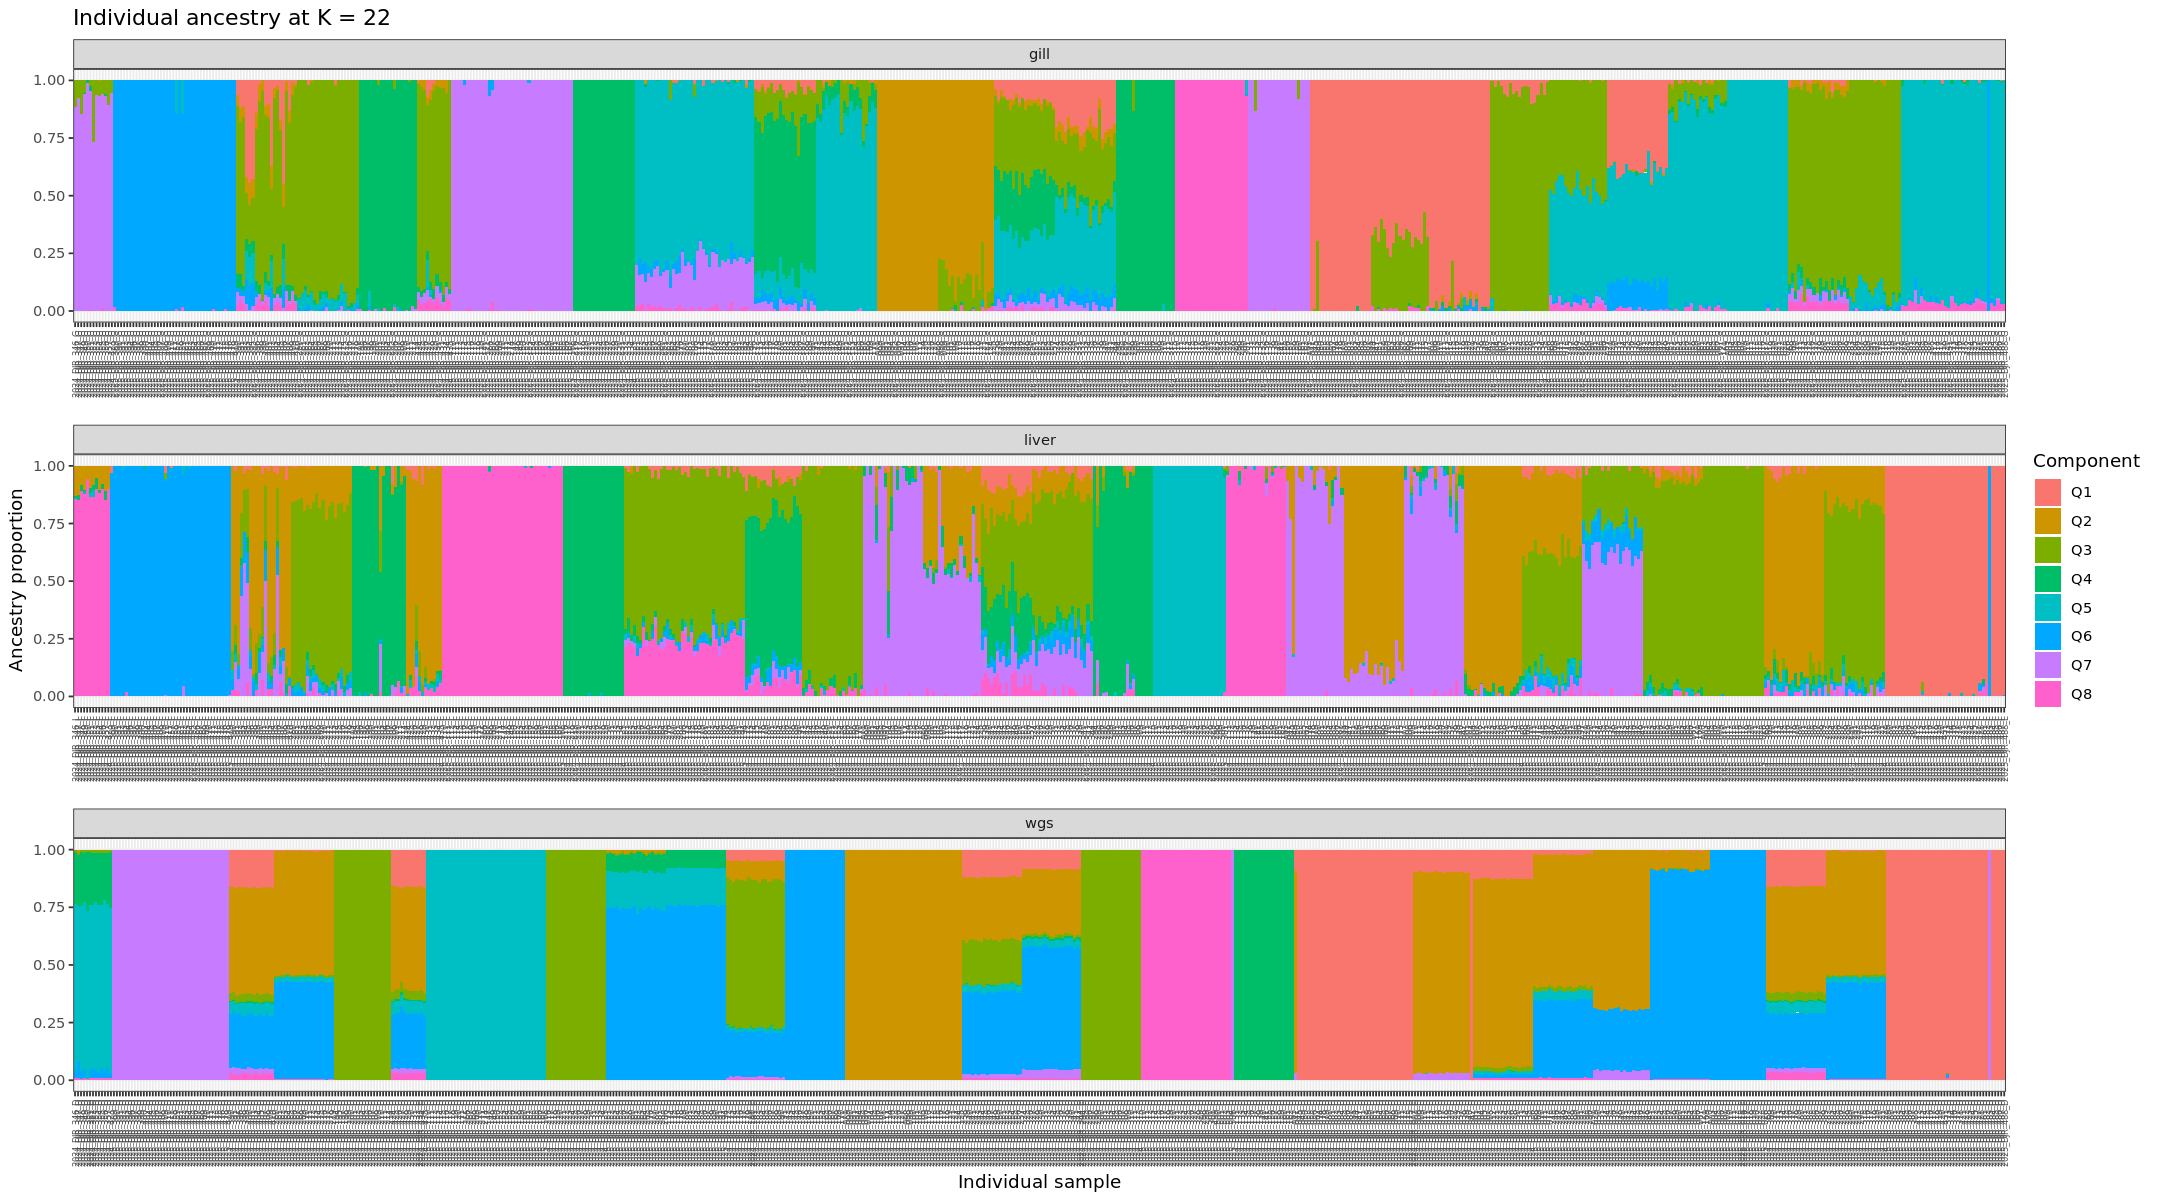

In [ ]:
options(repr.plot.width = 10, repr.plot.height = 6)

ancestry_individual <- ancestry %>%
  filter(!is.na(population)) %>%
  arrange(dataset, population, ecotype, analysis_id) %>%
  mutate(analysis_id = factor(analysis_id, levels = unique(analysis_id))) %>%
  pivot_longer(
    all_of(q_columns),
    names_to = "component",
    values_to = "proportion"
  )

options(repr.plot.width = 18, repr.plot.height = 10)

ggplot(ancestry_individual, aes(x = analysis_id, y = proportion, fill = component)) +
  geom_col(width = 1) +
  facet_wrap(~dataset, ncol = 1, scales = "free_x") +
  theme_bw() +
  theme(
    axis.text.x = element_text(angle = 90, hjust = 1, vjust = 0.5, size = 5),
    panel.spacing.y = unit(1, "lines")
  ) +
  labs(
    x = "Individual sample",
    y = "Ancestry proportion",
    fill = "Component",
    title = paste("Individual ancestry at K =", selected_k)
  )

In [33]:

population_modes <- ancestry %>% filter(!is.na(population), !is.na(top_component)) %>%
  count(dataset, population, ecotype, top_component, name = 'n') %>%
  group_by(dataset, population, ecotype) %>% slice_max(n, n = 1, with_ties = FALSE) %>%
  mutate(modal_fraction = n / sum(n)) %>% ungroup() %>%
  rename(population_modal_component = top_component)
ancestry_flags <- ancestry %>%
  left_join(population_modes %>% select(dataset, population, ecotype,
                                         population_modal_component, modal_fraction),
            by = c('dataset', 'population', 'ecotype')) %>%
  filter(!is.na(population_modal_component), top_ancestry >= 0.60,
         top_component != population_modal_component) %>%
  arrange(dataset, population, ecotype, desc(top_ancestry)) %>%
  select(dataset, analysis_id, base_id, population, ecotype, top_component, top_ancestry,
         population_modal_component, modal_fraction)
ancestry_flags

dataset,analysis_id,base_id,population,ecotype,top_component,top_ancestry,population_modal_component,modal_fraction
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<chr>,<dbl>
gill,2025_DJR_483_G,2025_DJR_483,Thiemer,stream,Q6,0.999930,Q5,1
liver,2024_DJR_049_L,2024_DJR_049,Paxton,benthic,Q2,0.816794,Q7,1
liver,2025_DJR_483_L,2025_DJR_483,Thiemer,stream,Q6,0.999930,Q1,1
wgs,2025_DJR_506_D,2025_DJR_506,Muchalat,stream,Q7,0.999930,Q8,1
wgs,2024_DJR_041_D,2024_DJR_041,Paxton,benthic,Q2,0.876793,Q1,1
wgs,2024_DJR_042_D,2024_DJR_042,Priest,benthic,Q1,0.999930,Q2,1
wgs,2025_DJR_483_D,2025_DJR_483,Thiemer,stream,Q7,0.999930,Q1,1


## Compare ancestry for the same fish across datasets

The next cell aligns component labels between WGS and each tissue using correlations across fish whose expected same-ID pair ranks first in relatedness. It then reports per-fish profile differences and whether the dominant component agrees after alignment. Review these flags with relatedness margin and population metadata.

In [ ]:
compare_ancestry_to_wgs <- function(tissue, tissue_dataset) {
  wgs <- ancestry %>% filter(dataset == 'wgs') %>% select(base_id, all_of(q_columns))
  brb <- ancestry %>% filter(dataset == tissue_dataset) %>% select(base_id, analysis_id, all_of(q_columns))
  w_names <- paste0('W', seq_along(q_columns)); b_names <- paste0('B', seq_along(q_columns))
  names(wgs)[match(q_columns, names(wgs))] <- w_names
  names(brb)[match(q_columns, names(brb))] <- b_names
  supported <- identity_qc %>% filter(tissue == !!tissue, expected_rank == 1) %>%
    transmute(base_id = sub('_[DGL]$', '', brb_id), relatedness_margin = expected_minus_alternative)
  paired <- inner_join(wgs, brb, by = 'base_id') %>% left_join(supported, by = 'base_id') %>%
    filter(!is.na(relatedness_margin))
  if (nrow(paired) < 3) { message('Too few supported pairs for ', tissue); return(NULL) }
  cors <- cor(as.matrix(paired[, w_names]), as.matrix(paired[, b_names]), use = 'pairwise.complete.obs')
  cors[!is.finite(cors)] <- -Inf
  remain_w <- seq_along(w_names); remain_b <- seq_along(b_names)
  alignment <- vector('list', length(w_names))
  for (i in seq_along(w_names)) {
    subcors <- cors[remain_w, remain_b, drop = FALSE]
    best <- which(subcors == max(subcors), arr.ind = TRUE)[1, ]
    wi <- remain_w[best[1]]; bi <- remain_b[best[2]]
    alignment[[i]] <- tibble(wgs_component = w_names[wi], brb_component = b_names[bi], correlation = cors[wi, bi])
    remain_w <- setdiff(remain_w, wi); remain_b <- setdiff(remain_b, bi)
  }
  alignment <- bind_rows(alignment)
  delta <- sapply(seq_along(w_names), function(i) paired[[alignment$wgs_component[i]]] - paired[[alignment$brb_component[i]]])
  w_top <- w_names[max.col(as.matrix(paired[, w_names]), ties.method = 'first')]
  b_top <- b_names[max.col(as.matrix(paired[, b_names]), ties.method = 'first')]
  mapped_b_top <- alignment$brb_component[match(w_top, alignment$wgs_component)]
  samples <- tibble(dataset = tissue_dataset, base_id = paired$base_id, brb_id = paired$analysis_id,
                    relatedness_margin = paired$relatedness_margin,
                    dominant_component_agrees = mapped_b_top == b_top,
                    mean_absolute_Q_difference = rowMeans(abs(delta))) %>% arrange(desc(mean_absolute_Q_difference))
  list(alignment = mutate(alignment, tissue = tissue), samples = samples)
}
comparisons <- Filter(Negate(is.null), list(compare_ancestry_to_wgs('gill', 'gill'),
                                               compare_ancestry_to_wgs('liver', 'liver')))
component_alignment <- bind_rows(lapply(comparisons, function(x) x[['alignment']]))
sample_ancestry_comparison <- bind_rows(lapply(comparisons, function(x) x[['samples']]))
component_alignment
sample_ancestry_comparison